# 02 - Normalization, integration and clustering

Takes the QC-passed cells from `01_qc_exploration.ipynb` and turns raw counts into clusters: normalize, pick highly variable genes, PCA, correct for sample effects with Harmony, then UMAP and Leiden clustering.

**Data**
- GSE150728 (Wilk et al. 2020, *Nature Medicine*), PBMCs from COVID-19 patients and healthy donors.

**Input**
- `results/qc/combined_qc.h5ad`: 46,431 cells x 40,448 genes, raw counts

**Outputs**
- `results/clustering/clustered.h5ad`: normalized `X`, raw counts in `layers["counts"]`, PCA, Harmony, UMAPs (before and after Harmony) and Leiden clusters
- `results/clustering/cluster_sample_mix.csv`: how evenly each cluster is spread across samples

## Setup

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import anndata
import harmonypy
from importlib.metadata import version
print("scanpy", version("scanpy"), "| anndata", version("anndata"), "| harmonypy", version("harmonypy"))

# Needed to save the .h5ad (string columns); reading it back needs AnnData >= 0.11
anndata.settings.allow_write_nullable_strings = True

RESULTS = "../results"
N_PCS   = 30                          # chosen from the variance plot in step 4
rng     = np.random.default_rng(0)    # for shuffling plot order

scanpy 1.11.5 | anndata 0.12.19 | harmonypy 2.1.0


## 1. Load and look at the raw counts

In [2]:
adata = sc.read_h5ad(f"{RESULTS}/qc/combined_qc.h5ad")
print(adata)

print("\nFirst 5 cells x 5 genes:")
print(adata.X[:5, :5].toarray())
print(f"\nNon-zero entries: {adata.X.nnz / (adata.n_obs * adata.n_vars):.1%}")
adata.obs["total_counts"].describe()

AnnData object with n_obs × n_vars = 46431 × 40448
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'sample', 'donor', 'condition', 'doublet_score', 'predicted_doublet'
    var: 'gene_name', 'mt', 'n_cells'
    layers: 'counts'

First 5 cells x 5 genes:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]

Non-zero entries: 3.1%


count    46431.000000
mean      2294.313993
std       1705.232391
min        799.000000
25%       1244.000000
50%       1711.000000
75%       2640.000000
max      14324.000000
Name: total_counts, dtype: float64

Only about 3% of the matrix is non-zero, which is why it's stored as a sparse matrix. UMIs per cell go from 799 to 14,324, an 18-fold range. A gene with 10 UMIs in a small cell and 10 UMIs in a big cell isn't equally expressed, so the counts need normalizing before cells can be compared.

## 2. Normalize

Each cell is scaled to 10,000 UMIs, then log(x + 1) is applied so a few very high genes don't dominate. The raw counts stay in `layers["counts"]` for later (pseudobulk and scVI need raw counts).

The first line resets `X` to raw counts, so running this cell twice doesn't log the data twice.

In [3]:
adata.X = adata.layers["counts"].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

print("Raw UMI totals (unchanged):        ", np.asarray(adata.layers["counts"][:3].sum(axis=1)).ravel())
print("Row sums after normalize (pre-log):", np.asarray(np.expm1(adata.X[:3]).sum(axis=1)).ravel().round(1))
print("Row sums after normalize + log:    ", np.asarray(adata.X[:3].sum(axis=1)).ravel().round(1))

Raw UMI totals (unchanged):         [2677. 2739. 1696.]
Row sums after normalize (pre-log): [10000. 10000. 10000.]
Row sums after normalize + log:     [2654.9 2769.8 2316.1]


The row sums aren't 10,000 anymore because the log is applied to each value separately. After the log, the sum roughly reflects how many genes a cell expresses.

## 3. Highly variable genes

Most genes are either barely detected or about the same in every cell, so they mainly add noise. The 2,000 genes that vary most between cells are kept.

- `flavor="seurat_v3"` models raw counts, so it reads `layers["counts"]`.
- `batch_key="sample"` picks genes that vary within samples, so genes that only mark one donor are less likely to be picked.
- `span=0.5`: with the default (0.3) the curve fit failed ("reciprocal condition number"), probably because small samples have many low-count genes. A larger span gives a smoother, more stable fit.

In [4]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat_v3",
    layer="counts",
    batch_key="sample",
    span=0.5,
)

print(f"Highly variable genes selected: {adata.var['highly_variable'].sum()}")
display(adata.var[adata.var["highly_variable"]]
        .sort_values("highly_variable_rank")
        .head(20)[["gene_name"]]
        .rename(columns={"gene_name": "top 20 HVGs"}))

Highly variable genes selected: 2000


,top 20 HVGs
gene_id,
ENSG00000211592.8,IGKC
ENSG00000132465.12,JCHAIN
ENSG00000211895.5,IGHA1
ENSG00000244734.4,HBB
ENSG00000211677.2,IGLC2
ENSG00000271178.1,IGHV3OR16-13
ENSG00000211899.10,IGHM
ENSG00000211896.7,IGHG1
ENSG00000188536.13,HBA2


The top 20 line up with the main cell populations described in the paper:
- **Antibody genes** (IGKC, JCHAIN, IGHA1, IGHG1, MZB1...): plasmablasts, which expand in severe COVID
- **S100A8, S100A9, LYZ, VCAN**: classical monocytes
- **DEFA3**: developing neutrophils
- **MKI67**: dividing cells
- **HBB, HBA2**: leftover red-cell RNA

Antibody V genes (like `IGHV3OR16-13`) vary between B-cell clones rather than cell types. They are kept for now; if B cells or plasmablasts split into clusters without a clear reason, the V/D/J genes could be removed from the HVGs.

## 4. PCA

PCA summarizes the 2,000 HVGs into 50 components. Genes are scaled to mean 0 and variance 1 first so highly expressed genes don't dominate. Scaling turns the sparse matrix into a dense one (every zero becomes a stored value), so only a copy with the 2,000 HVGs is scaled. Scaling all 40,448 genes would mean storing 46,431 × 40,448 values at 4 bytes each, about 7.5 GB.

/opt/anaconda3/envs/scrna/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


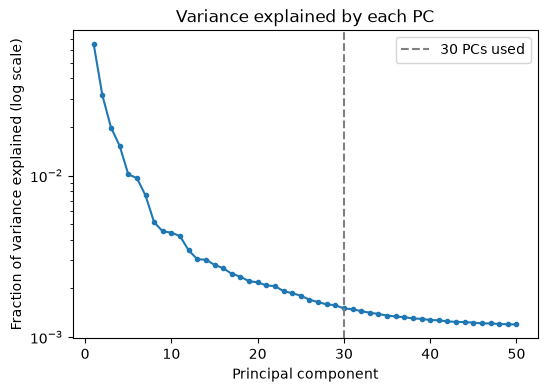

In [5]:
hvg = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(hvg, max_value=10)   # clips extreme values at 10 SDs
sc.pp.pca(hvg, n_comps=50)

adata.obsm["X_pca"] = hvg.obsm["X_pca"]
adata.uns["pca"] = hvg.uns["pca"]
del hvg                          # free the dense copy

var_ratio = adata.uns["pca"]["variance_ratio"]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(1, len(var_ratio) + 1), var_ratio, "o-", markersize=3)
ax.set_yscale("log")
ax.axvline(N_PCS, ls="--", c="grey", label=f"{N_PCS} PCs used")
ax.set_xlabel("Principal component")
ax.set_ylabel("Fraction of variance explained (log scale)")
ax.set_title("Variance explained by each PC")
ax.legend()
plt.show()

The curve drops steeply until about PC8-10 and flattens around PC15-20. 30 PCs are used, a bit past the bend, so small cell types that only show up in later PCs aren't lost.

### What the first PCs separate

Plots are drawn in a shuffled order, since otherwise the last group drawn covers everything underneath (in the first version, Healthy cells hid most of the COVID cells).

/opt/anaconda3/envs/scrna/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


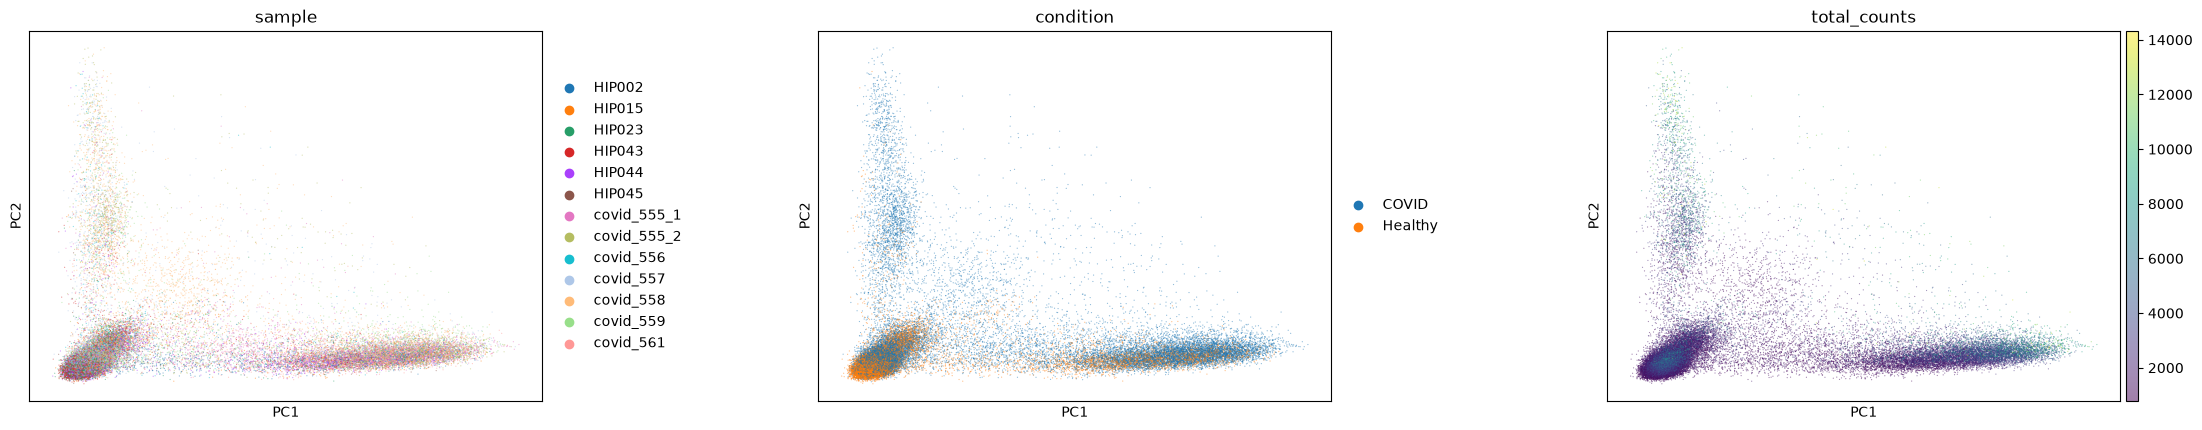

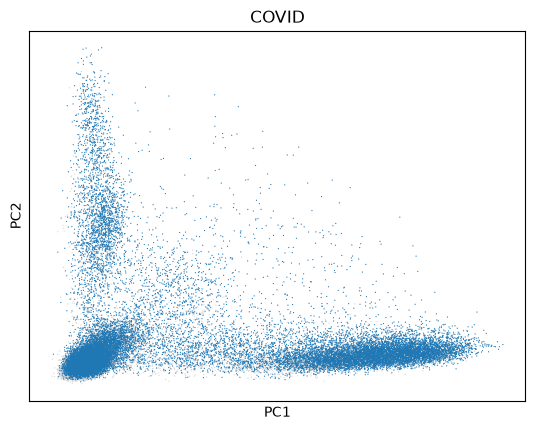

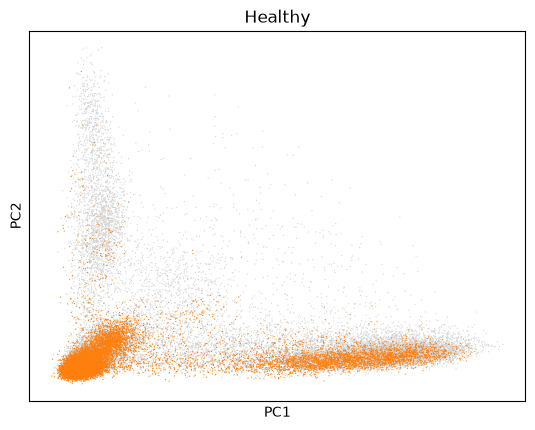

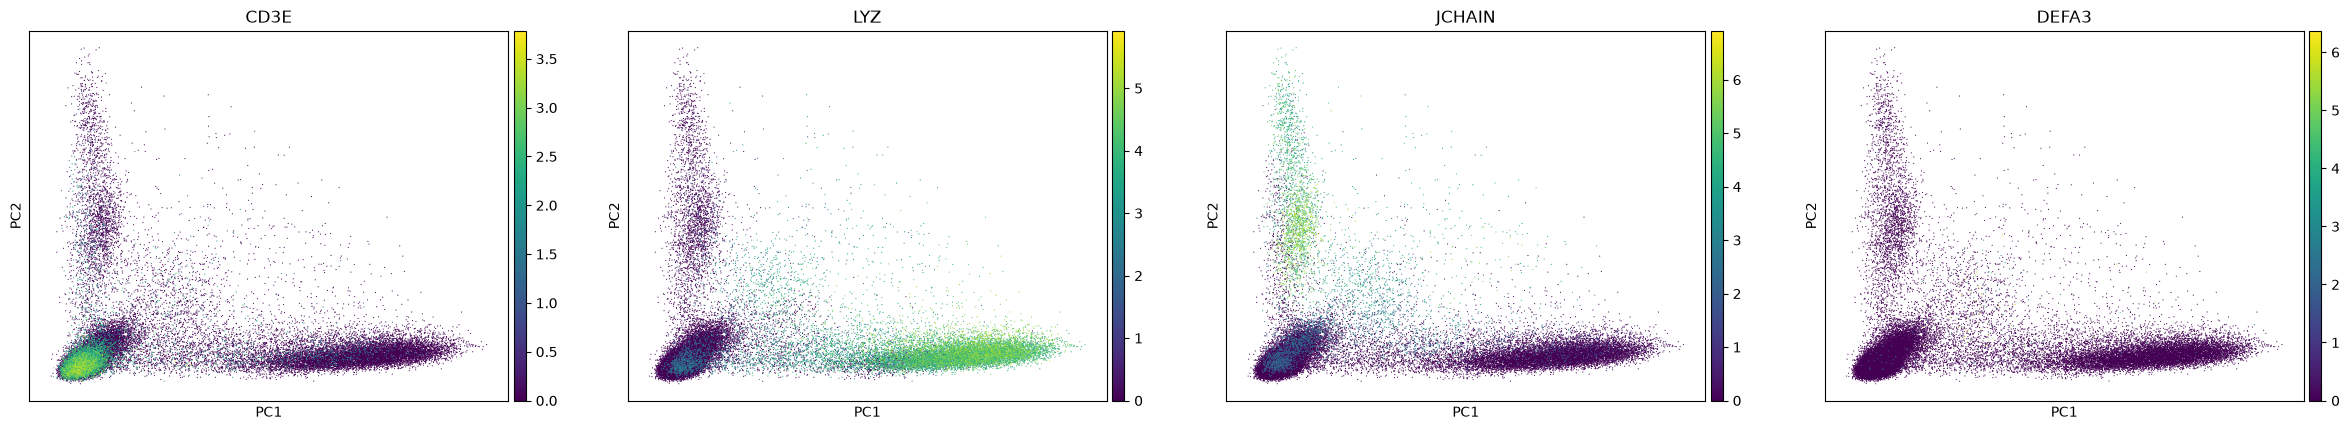

In [6]:
shuffled = adata[rng.permutation(adata.n_obs)]
sc.pl.pca(shuffled, color=["sample", "condition", "total_counts"], size=3, alpha=0.5, ncols=3, wspace=0.4)

for cond in ["COVID", "Healthy"]:
    sc.pl.pca(adata, color="condition", groups=[cond], size=3, title=cond, legend_loc=None)

sc.pl.pca(adata, color=["CD3E", "LYZ", "JCHAIN", "DEFA3"], gene_symbols="gene_name", ncols=4)

The PCA shows three arms: lymphocytes bottom-left (bright in the CD3E panel), monocytes along PC1 (LYZ panel) and plasmablasts along PC2 (JCHAIN panel). The plasmablast arm is almost all COVID. DEFA3 doesn't mark any arm, suggesting developing neutrophils are too few to show up in PC1/PC2.

UMIs change between arms rather than as a smooth gradient across all cells, so the PCs seem to follow cell types (which differ in RNA content) rather than capture depth.

In the JCHAIN panel, the bottom-left lymphocyte blob (where CD3E is highest) is also faintly colored. T cells don't produce antibodies, so this is likely ambient RNA from plasmablasts, which matters for differential expression later.

## 5. UMAP before integration (baseline)

The neighbor graph links each cell to its 15 most similar cells (in 30 PCs), and UMAP draws that graph in 2D. This uncorrected UMAP is kept to compare with the Harmony result.

/opt/anaconda3/envs/scrna/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/anaconda3/envs/scrna/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


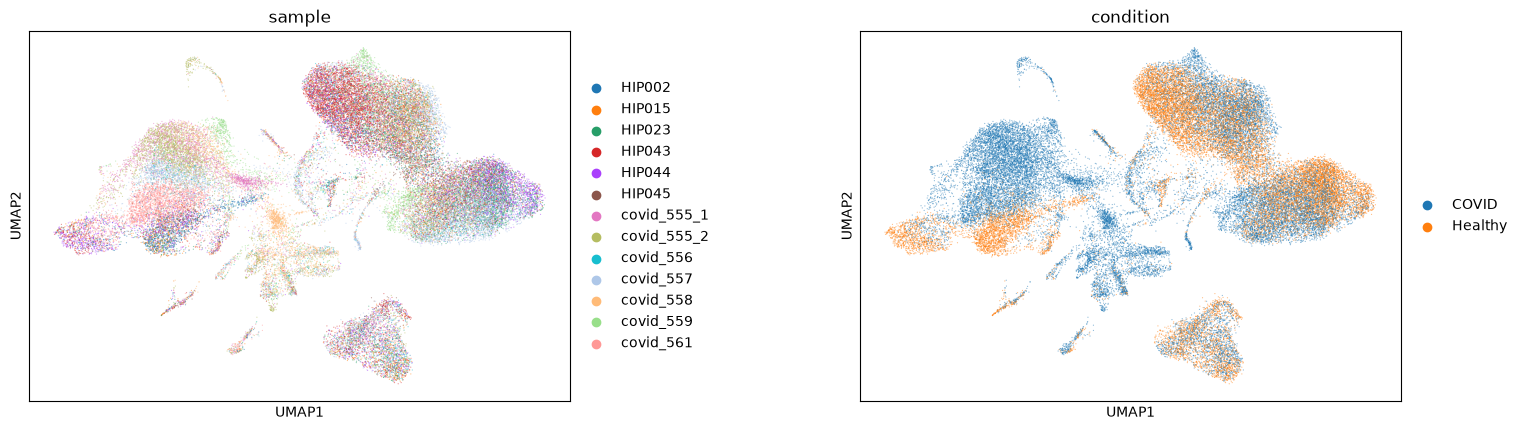

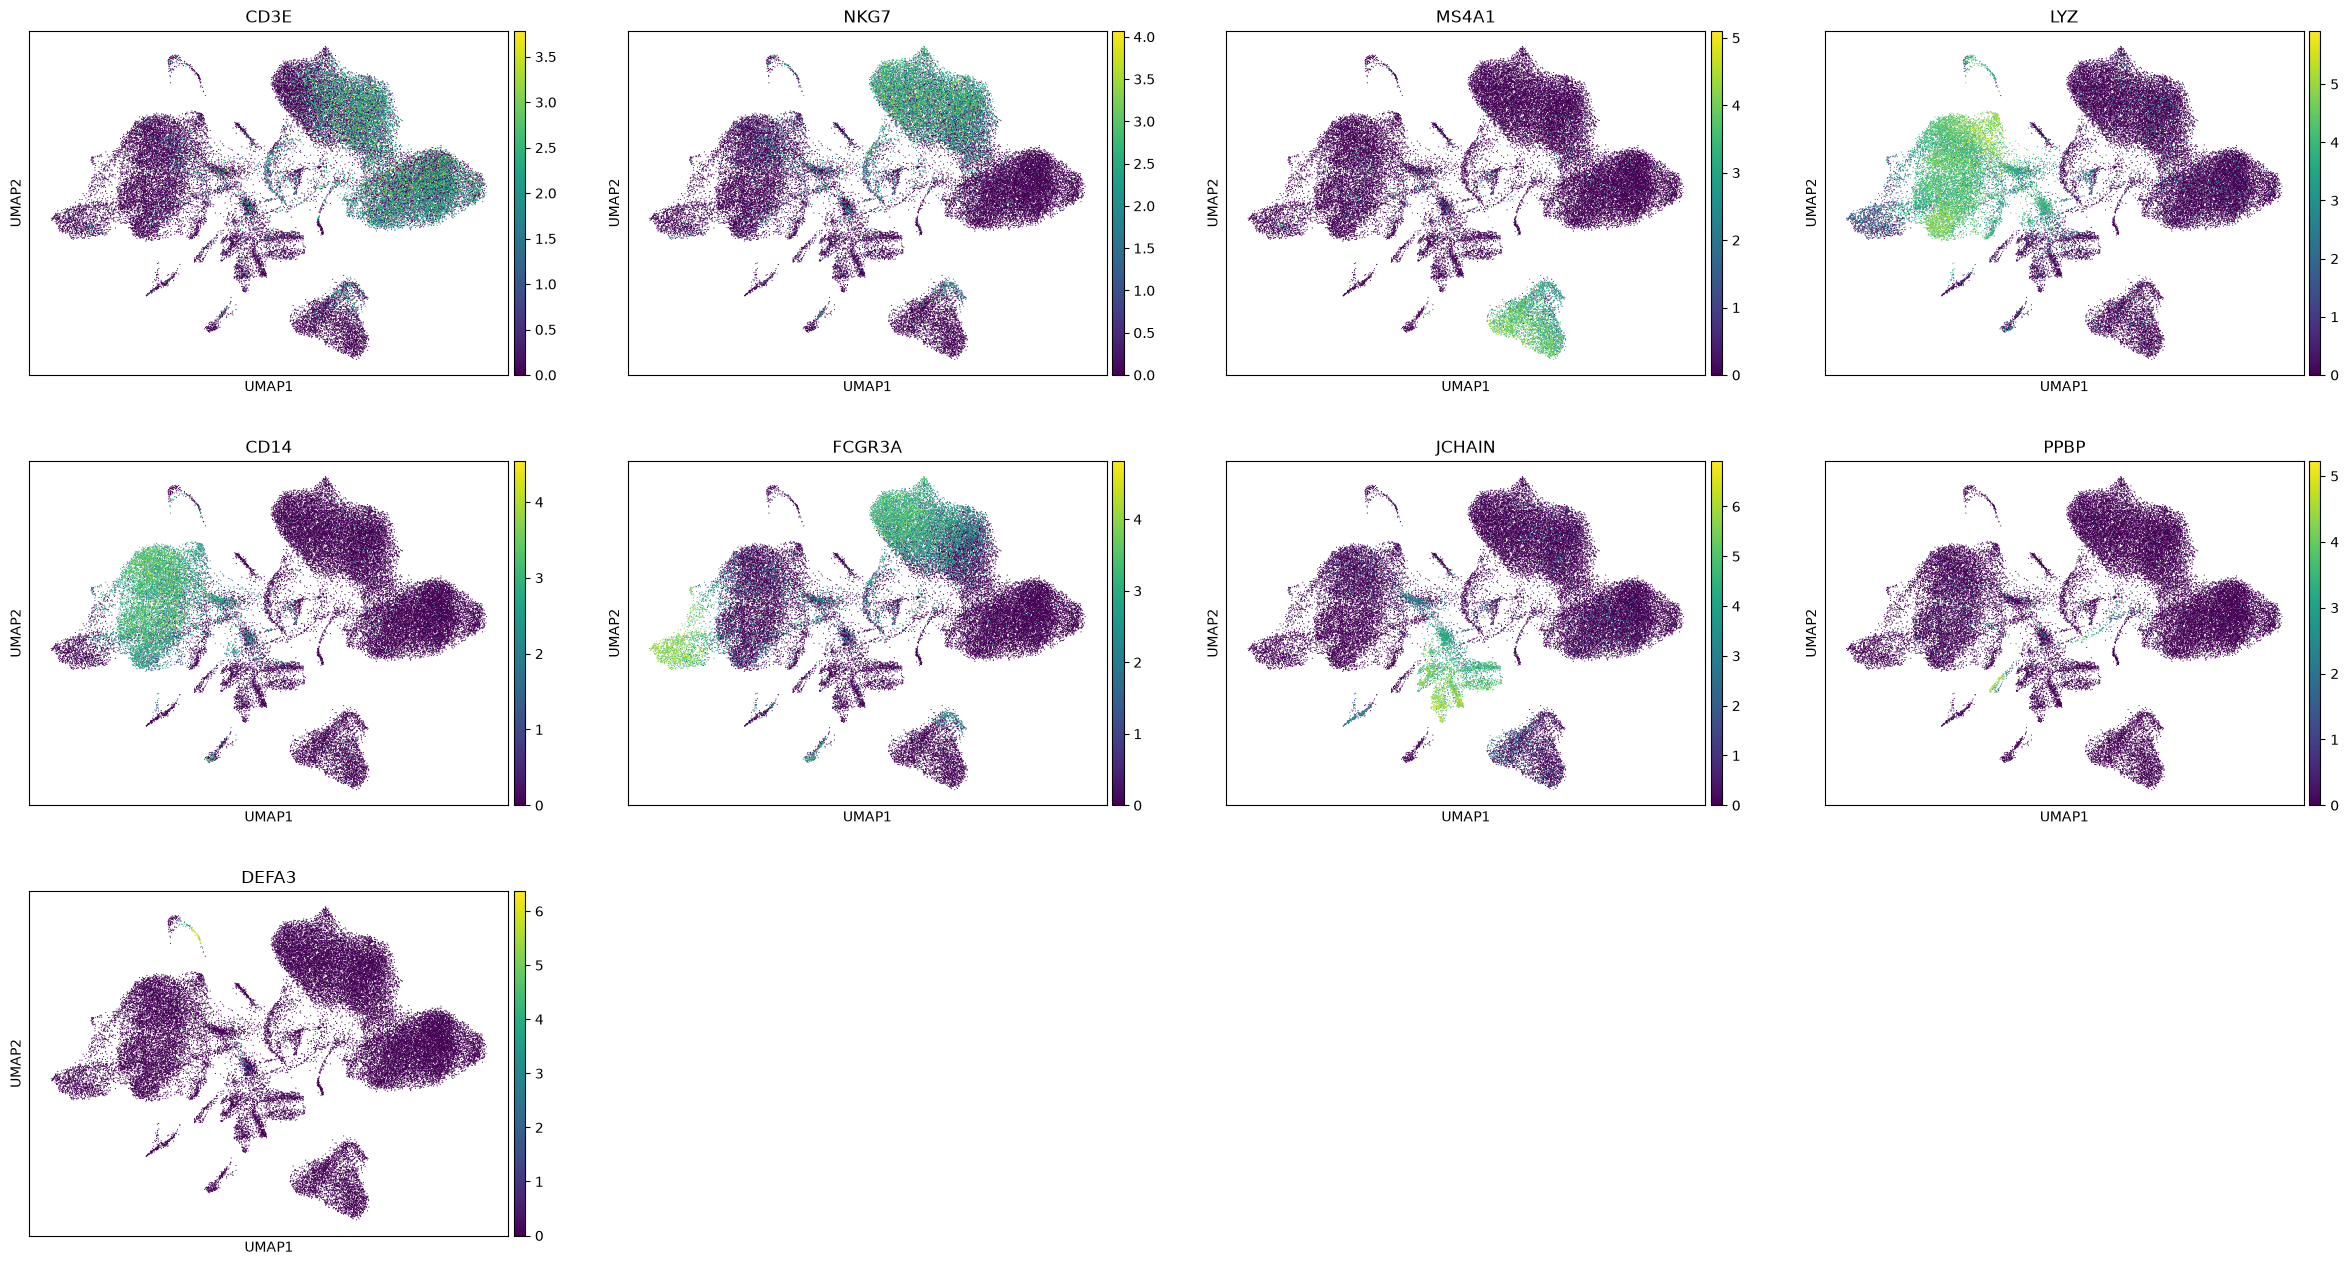

In [7]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=N_PCS, use_rep="X_pca")
sc.tl.umap(adata, random_state=0)
adata.obsm["X_umap_uncorrected"] = adata.obsm["X_umap"].copy()

shuffled = adata[rng.permutation(adata.n_obs)]
sc.pl.umap(shuffled, color=["sample", "condition"], size=3, alpha=0.5, wspace=0.4)
sc.pl.umap(
    adata,
    color=["CD3E", "NKG7", "MS4A1", "LYZ", "CD14", "FCGR3A", "JCHAIN", "PPBP", "DEFA3"],
    gene_symbols="gene_name",
    ncols=4,
)

The markers match the PCA. CD14 monocytes (LYZ, CD14) are upper left and mostly COVID, while CD16 monocytes (FCGR3A) form the lower-left arm and are mostly healthy. NK and cytotoxic T cells (NKG7) sit top right, also mostly healthy, with the other T cells (CD3E) just below. B cells (MS4A1) are at the bottom, plasmablasts (JCHAIN) in the middle (COVID only), and there are small groups of platelets (PPBP) and developing neutrophils (DEFA3).

The COVID vs Healthy split first looked like a batch effect, but the markers show it is mostly different cell types: COVID samples have more CD14 monocytes and fewer CD16 monocytes and NK cells. The part that looks technical is samples forming their own patches within an island, e.g. covid_561 and covid_555_2 inside the CD14 monocytes.

Since every sample is either COVID or Healthy, disease and batch can't be fully separated. Harmony is used here only to find and name cell types; the COVID vs Healthy comparison later goes back to raw counts with donors as replicates.

## 6. Harmony integration

Harmony shifts each sample's cells in PCA space until samples mix within each cell type. It changes only the PCA coordinates, not the counts. The batch key is `sample` (the array) rather than `donor`, since covid_555_1 and covid_555_2 are the same patient on two arrays.

harmonypy is called directly because scanpy's `harmony_integrate` wrapper transposes the output, and harmonypy 2.x already returns cells x PCs, which gives a shape error.

In [8]:
ho = harmonypy.run_harmony(adata.obsm["X_pca"], adata.obs, "sample", random_state=0)

Z = np.asarray(ho.Z_corr)
if Z.shape[0] != adata.n_obs:      # older harmonypy returns PCs x cells
    Z = Z.T
assert Z.shape == adata.obsm["X_pca"].shape
adata.obsm["X_pca_harmony"] = Z

2026-10-26 10:39:59,723 - harmonypy - INFO - Running Harmony
2026-10-26 10:39:59,723 - harmonypy - INFO -   Parameters:
2026-10-26 10:39:59,723 - harmonypy - INFO -     max_iter_harmony: 10
2026-10-26 10:39:59,725 - harmonypy - INFO -     max_iter_kmeans: 4
2026-10-26 10:39:59,726 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-10-26 10:39:59,729 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-10-26 10:39:59,731 - harmonypy - INFO -     nclust: 100
2026-10-26 10:39:59,738 - harmonypy - INFO -     block_size: 0.05
2026-10-26 10:39:59,738 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-10-26 10:39:59,739 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
2026-10-26 10:39:59,739 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-10-26 10:39:59,740 - harmonypy - INFO -     verbose: True
2026-10-26 10:39:59,740 - harmonypy - INFO -     random_state: 0
2026-10-26 10:39:59,740 - harmonypy - INFO -   Data: 50 PCs × 46431 cells
2026-10-26 10:39:

/opt/anaconda3/envs/scrna/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


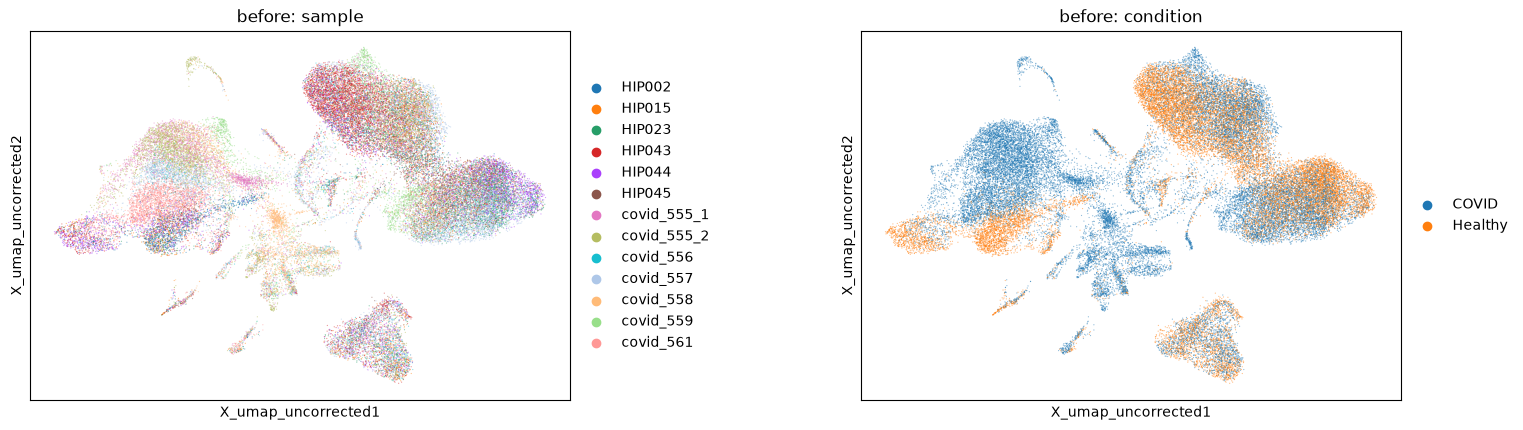

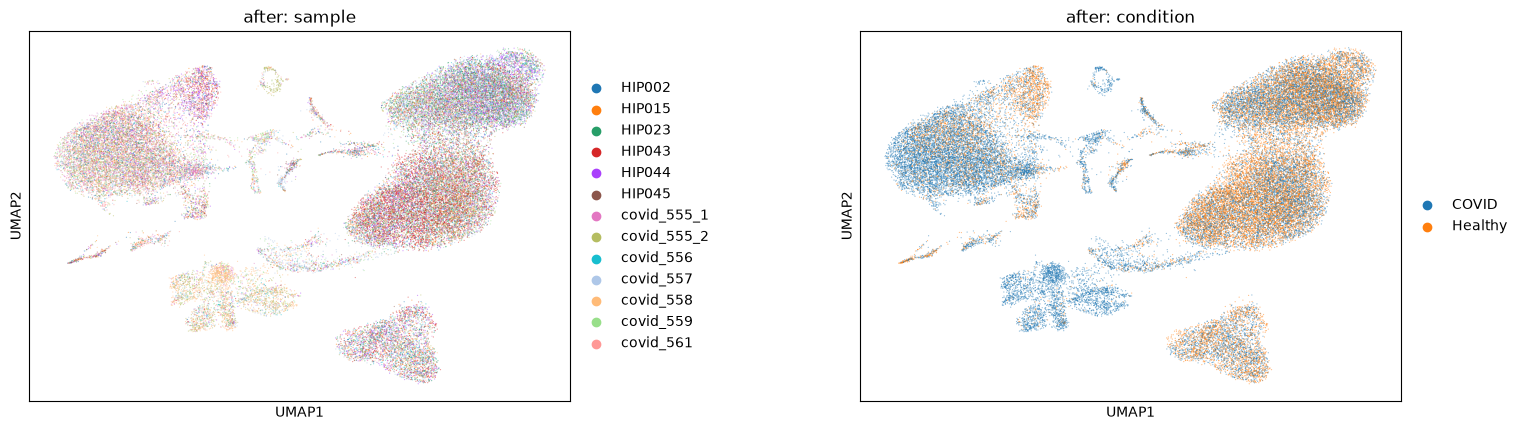

In [9]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=N_PCS, use_rep="X_pca_harmony")
assert adata.uns["neighbors"]["params"]["use_rep"] == "X_pca_harmony"
sc.tl.umap(adata, random_state=0)

shuffled = adata[rng.permutation(adata.n_obs)]
sc.pl.embedding(shuffled, basis="X_umap_uncorrected", color=["sample", "condition"], size=3, alpha=0.5, wspace=0.4,
                title=["before: sample", "before: condition"])
sc.pl.umap(shuffled, color=["sample", "condition"], size=3, alpha=0.5, wspace=0.4,
           title=["after: sample", "after: condition"])

After Harmony the sample patches are gone and T, NK and B cells mix across all samples. The COVID-only plasmablasts remain a separate cluster (Harmony can't merge cells that have no match in other samples), and the monocyte island is still mostly COVID, since integration doesn't change how many cells each sample has.

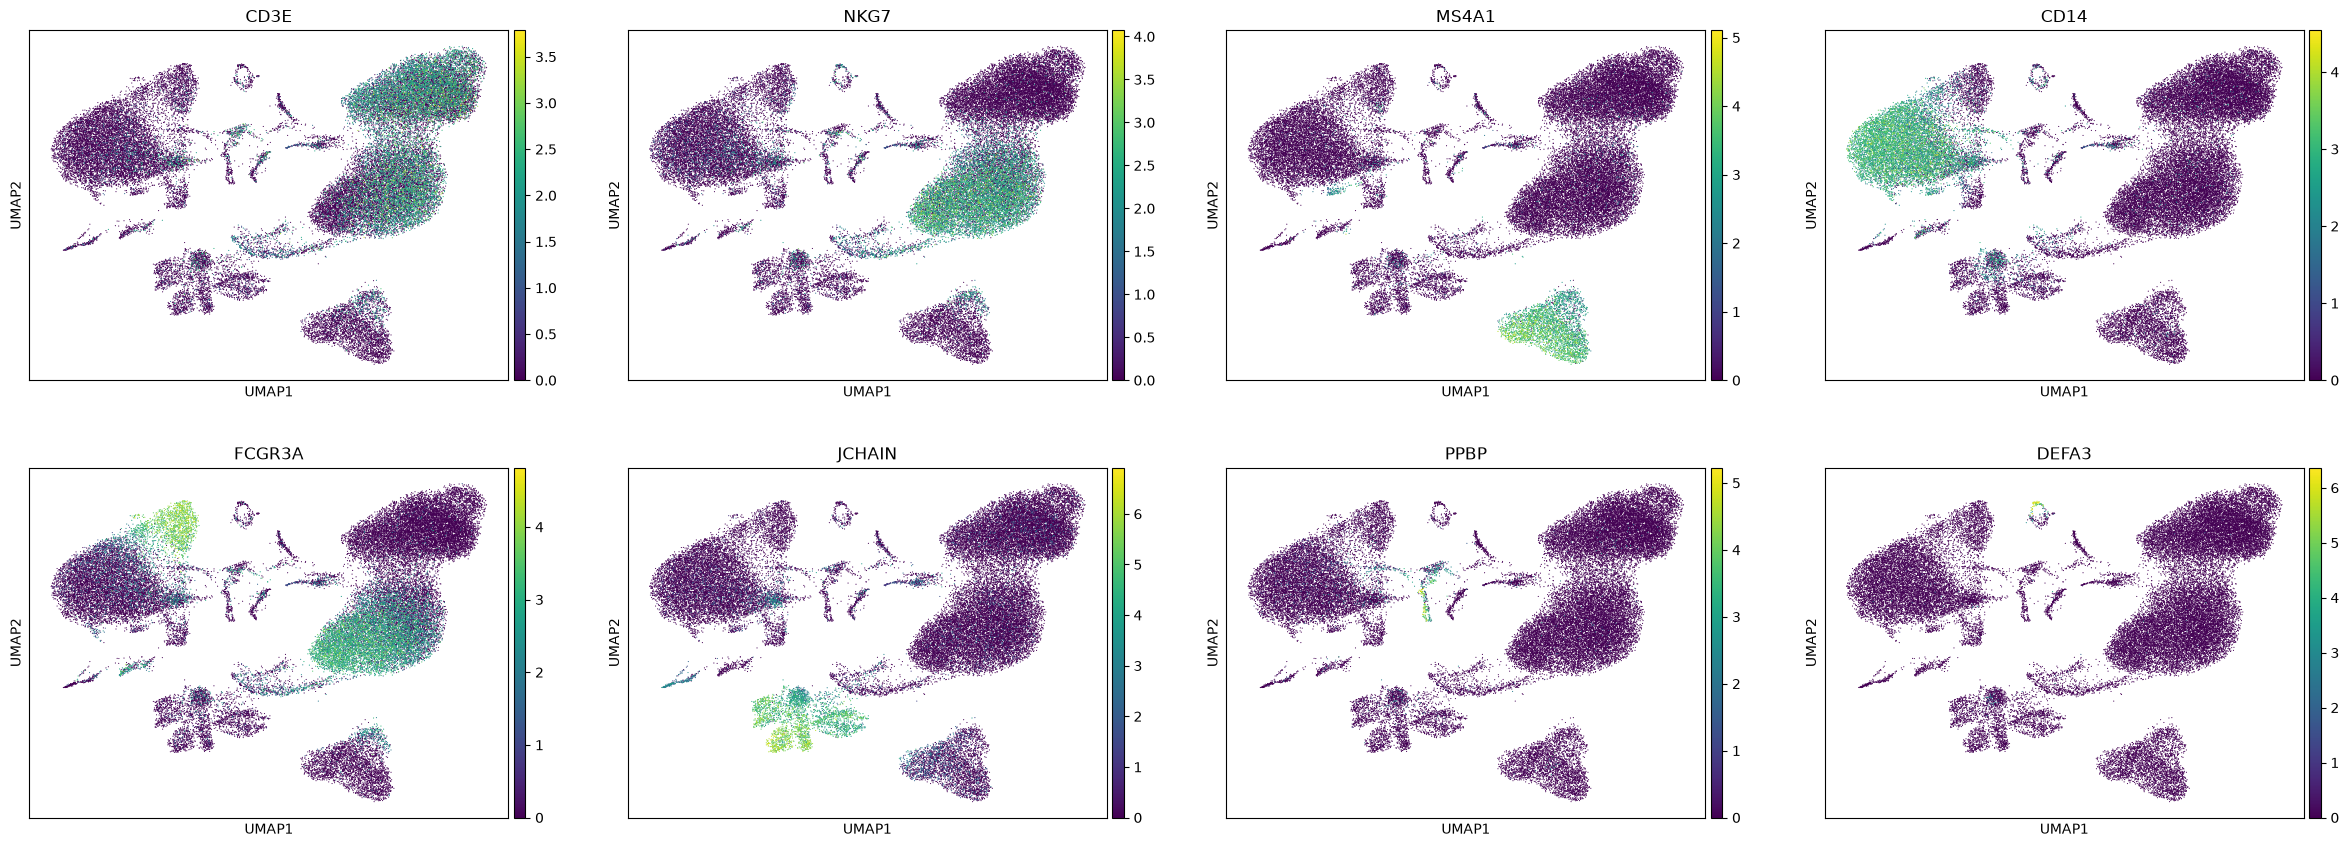

In [10]:
sc.pl.umap(
    adata,
    color=["CD3E", "NKG7", "MS4A1", "CD14", "FCGR3A", "JCHAIN", "PPBP", "DEFA3"],
    gene_symbols="gene_name",
    ncols=4,
)

To check for overcorrection: CD14 and FCGR3A still mark separate parts of the monocyte island, and T cells, NK cells, B cells, plasmablasts, platelets and developing neutrophils each keep their own region. A small spot inside the plasmablast cluster shows faint CD14, NKG7 and DEFA3 together, a possible doublet signal to check during annotation.

## 7. Leiden clustering

Leiden splits the neighbor graph (built on the Harmony space, not the 2D UMAP) into groups of tightly connected cells. `resolution` controls how many clusters come out, so two values are compared.

Resolution 0.5: 15 clusters
Resolution 1.0: 21 clusters


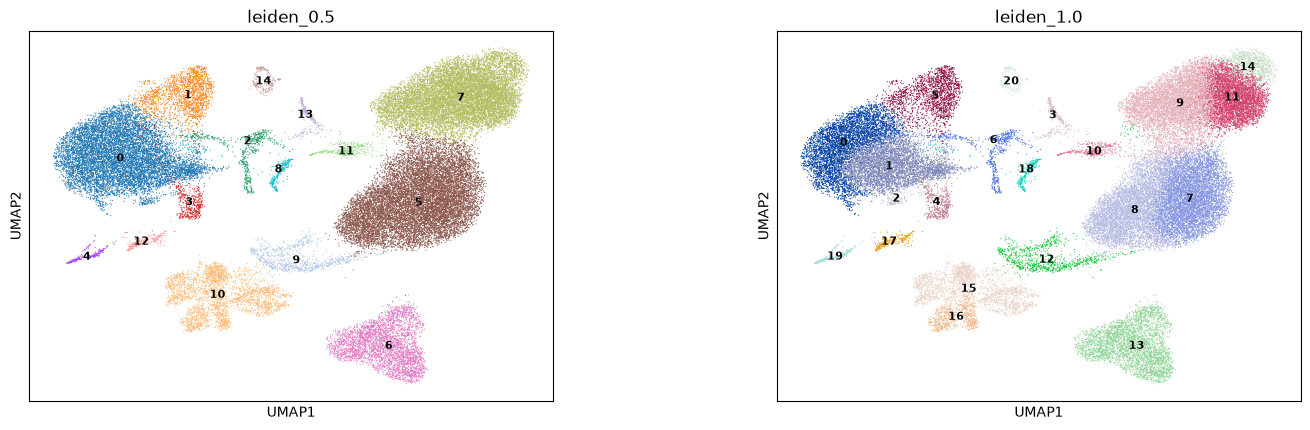

In [11]:
for res in [0.5, 1.0]:
    sc.tl.leiden(adata, resolution=res, key_added=f"leiden_{res}", flavor="igraph", n_iterations=2, random_state=0)
    print(f"Resolution {res}: {adata.obs[f'leiden_{res}'].nunique()} clusters")

sc.pl.umap(adata, color=["leiden_0.5", "leiden_1.0"], legend_loc="on data", legend_fontsize=8, wspace=0.3)

Resolution 0.5 gives 15 clusters and 1.0 gives 21. At 0.5 the clusters mostly match the islands above (likely 0 CD14 monocytes, 1 CD16 monocytes, 5 NK/cytotoxic, 6 B cells, 7 T cells, 10 plasmablasts, 14 developing neutrophils, with several small clusters to identify). At 1.0 the CD14 monocytes, T cells, NK cells and plasmablasts split further, which could be real cell states or one population divided into pieces.

### Is any cluster mostly one sample?

`top_frac` is the share of the cluster that comes from its biggest sample. With 13 libraries sharing evenly, that would be about 0.08.

In [12]:
ct = pd.crosstab(adata.obs["leiden_0.5"], adata.obs["sample"])
frac = ct.div(ct.sum(axis=1), axis=0)   # each row adds up to 1

sample_mix = pd.DataFrame({
    "n_cells": ct.sum(axis=1),
    "top_sample": frac.idxmax(axis=1),
    "top_frac": frac.max(axis=1).round(2),
    "n_samples_over_1pct": (frac > 0.01).sum(axis=1),
}).rename_axis("cluster").sort_values("top_frac", ascending=False)
sample_mix

,n_cells,top_sample,top_frac,n_samples_over_1pct
cluster,,,,
14,204,covid_555_2,0.58,8
10,2936,covid_558,0.46,9
9,852,covid_557,0.40,12
8,282,covid_557,0.36,12
12,230,covid_561,0.31,12
5,13093,HIP043,0.27,13
13,278,covid_558,0.25,12
7,11918,covid_557,0.24,13
1,1669,HIP044,0.23,12


13 of 15 clusters contain cells from at least 12 samples, and no single sample makes up more than 31% of them. Two clusters are dominated by one sample:
- **Cluster 14 (developing neutrophils):** 58% from covid_555_2, with only 8 samples above 1%.
- **Cluster 10 (plasmablasts):** 46% from covid_558. Every COVID patient has some, but one has far more.

For these two, a pooled-cell comparison would mostly reflect one patient, so the disease comparison needs to count patients rather than cells.

## 8. Save

In [13]:
os.makedirs(f"{RESULTS}/clustering", exist_ok=True)
adata.write_h5ad(f"{RESULTS}/clustering/clustered.h5ad")
sample_mix.to_csv(f"{RESULTS}/clustering/cluster_sample_mix.csv")
adata

AnnData object with n_obs × n_vars = 46431 × 40448
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'sample', 'donor', 'condition', 'doublet_score', 'predicted_doublet', 'leiden_0.5', 'leiden_1.0'
    var: 'gene_name', 'mt', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'log1p', 'hvg', 'pca', 'condition_colors', 'neighbors', 'umap', 'leiden_0.5', 'leiden_1.0', 'leiden_0.5_colors', 'leiden_1.0_colors'
    obsm: 'X_pca', 'X_umap', 'X_umap_uncorrected', 'X_pca_harmony'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

## Summary

46,431 cells in 15 clusters (resolution 0.5) after Harmony on sample. So far the largest COVID vs Healthy differences are in which cell types are present rather than in how they look.